# Drawing heart curves with Python

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 06 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/06_Drawing_Heart_Curves.ipynb)

**Audience:** first-year engineering students. No calculus, computer graphics, or prior knowledge of plane curves is assumed.

**A question for a design studio:** How can a short equation become a smooth, reproducible drawing? A plotter, graphics program, or laser cutter ultimately needs positions. Python lets us compute a sequence of positions, check the geometry, compare designs, and export crisp vector graphics. The curves here are dimensionless mathematical outlines, not machine-ready manufacturing paths.

There is no single equation for “the heart.” We will draw several from the [MathWorld Heart Curve entry](https://mathworld.wolfram.com/HeartCurve.html) and its companion Mathematica notebook, then examine the reflected-ellipse construction discussed by [Nick on Mathematics Stack Exchange](https://math.stackexchange.com/a/969748) and [Frederick Wu on Wolfram Community](https://community.wolfram.com/t/various-heart-shaped-curves-from-a-japanese-series/25155/7). All Python code and plots below are newly written; Mathematica is not needed to run this notebook.

**What you will learn:** make coordinate arrays, write functions, loop over design choices, transform shapes, use equal-axis scaling, turn polar and implicit equations into plots, test symmetry and equation residuals, and study how sampling changes a drawing. Read a section, predict its result, then run the next cell. Every executable code line has an adjacent explanatory comment.


<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 2, Collections and data |
| **Time** | about 35 min (about 70 min with exercises) |
| **Before this** | Notebook 05, Section 0 (NumPy arrays). |
| **Essential** | Sections 1–5 and 9. |
| **Optional on a first reading** | Sections 6–8; the gallery, notebook 06b (filled curves, 3D and animation). |
| **Next** | 06b (optional), then 07. |

**You have understood this notebook if you can, without looking back:**

1. Explain how `np.linspace` and a parametric formula turn a list of angles into an (x, y) curve, and why `plt.axis('equal')` matters.
2. Write a function that returns the x and y arrays of a curve, and check its left–right symmetry with an `assert`.
3. Predict how the drawing changes with 10, 100 and 1000 points, and choose a sensible number.
4. Scale, shift or stretch a curve using array arithmetic only, without a loop.
5. Say how a parametric, a polar and an implicit curve differ, and which Matplotlib call draws each one.

**Not expected of you:** The area derivation in Sections 7–8.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 1. From an angle to a plotted line

A *parameter* is a number we choose and vary. A **parametric curve** gives both coordinates as functions of that number: $(x(t),y(t))$. If we sample $t$ at many values, Python computes pairs of coordinates and joins them in order. This is useful when a shape folds back on itself and cannot be described by one single-valued function $y=f(x)$.

We use NumPy for arrays and trigonometric functions, Matplotlib for graphics, and pathlib to save figures. Angles passed to NumPy's sine and cosine are in **radians**, so a full turn is $2\pi$. Coordinates are dimensionless throughout.


In [1]:
# Import Path so figure exports have clear, portable filenames.
from pathlib import Path
# Import NumPy for arrays, trigonometry, and numerical checks.
import numpy as np
# Import Matplotlib's plotting interface for the figures.
import matplotlib.pyplot as plt
# Use a consistent plotting theme with readable fonts and editable SVG text.
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "savefig.dpi": 300, "svg.fonttype": "none"})
# Store recurring colors in a dictionary to avoid unexplained color codes later.
colors = {"rose": "#B63E5A", "blue": "#2F7896", "gold": "#C48733", "ink": "#26374A", "gray": "#9AA6B2"}
# Make a folder for vector and raster exports when students run the notebook.
figure_dir = Path("heart_curve_figures")
# Create the folder if it is not already present.
figure_dir.mkdir(exist_ok=True)
# Define one helper so every figure is exported in the same two formats.
def finish_figure(fig, stem):
    # Explain the file outputs in the function's own documentation.
    '''Save an SVG and a 300 dpi PNG, then display the figure.'''
    # Save a scalable vector copy for later editing or publication.
    fig.savefig(figure_dir / f"{stem}.svg", bbox_inches="tight", facecolor="white")
    # Save a high-resolution raster copy for software without SVG support.
    fig.savefig(figure_dir / f"{stem}.png", dpi=300, bbox_inches="tight", facecolor="white")
    # Display the figure directly in Jupyter and in the saved notebook.
    plt.show()


A circle is our control example: $x(t)=\cos t$, $y(t)=\sin t$. Every point should satisfy $x^2+y^2=1$. **Predict:** where is the point when $t=0$? When $t=\pi/2$? The identity gives us a check beyond “the plot looks round.”


In [2]:
# Sample one full turn, including the final point so the path closes.
angles = np.linspace(0.0, 2.0 * np.pi, 241)
# Convert each angle into a horizontal circle coordinate.
circle_x = np.cos(angles)
# Convert the same angles into vertical circle coordinates.
circle_y = np.sin(angles)
# Verify the defining equation at every sampled point.
assert np.allclose(circle_x**2 + circle_y**2, 1.0, atol=1e-14)
# Report the start point, where cos(0)=1 and sin(0)=0.
print(f"Circle starts at ({circle_x[0]:.1f}, {circle_y[0]:.1f}).")


Circle starts at (1.0, 0.0).


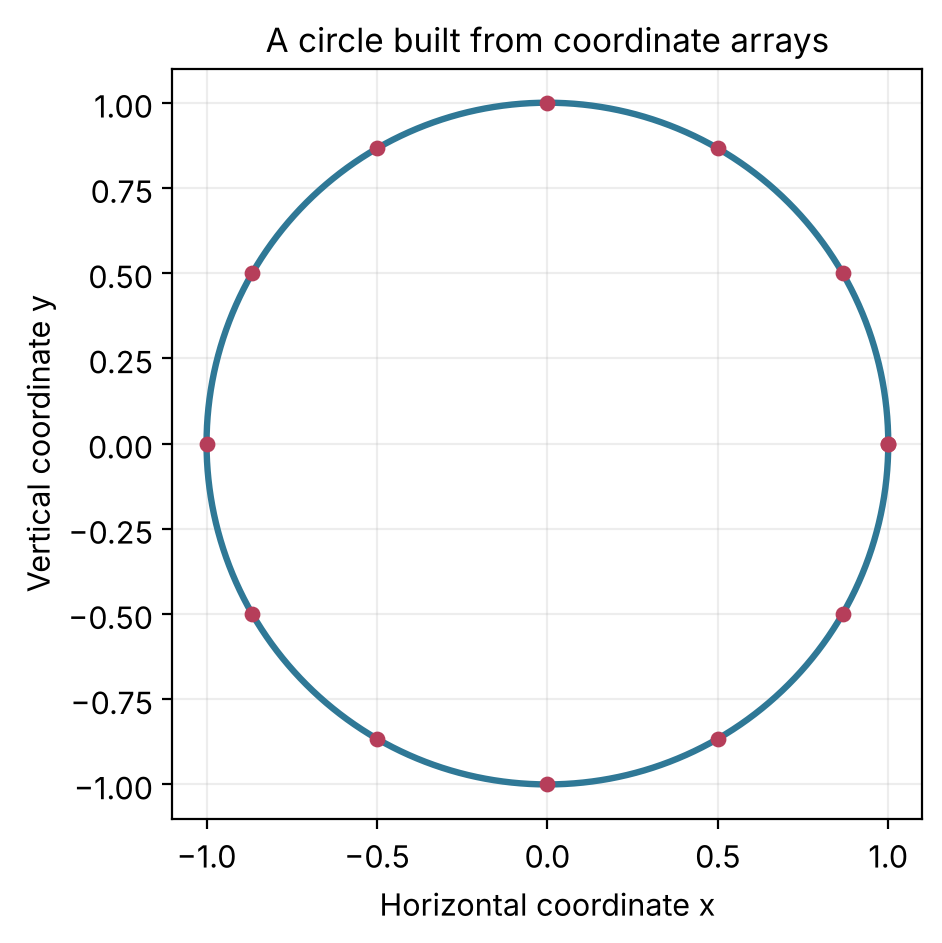

In [3]:
# Create a compact axes for the first coordinate drawing.
fig, ax = plt.subplots(figsize=(5.1, 4.6), layout="constrained")
# Join the sampled points in their parameter order.
ax.plot(circle_x, circle_y, color=colors["blue"], lw=2.3)
# Show every twentieth point so the sampling process remains visible.
ax.scatter(circle_x[::20], circle_y[::20], color=colors["rose"], s=22, zorder=3)
# Keep one horizontal data unit the same physical length as one vertical unit.
ax.set_aspect("equal", adjustable="box")
# Label both dimensionless coordinate axes explicitly.
ax.set(xlabel="Horizontal coordinate x", ylabel="Vertical coordinate y", title="A circle built from coordinate arrays")
# Add a faint reference grid for reading points.
ax.grid(alpha=0.22)
# Export both formats and show the figure.
finish_figure(fig, "01_circle_coordinates")


**Figure 1.** A line joins successive coordinate pairs. The dots reveal that the curve is made from a finite sample, even though it looks smooth.


## 2. A familiar heart from trigonometric functions

MathWorld lists the parametric curve
$$
x(t)=16\sin^3 t,\qquad
y(t)=13\cos t-5\cos(2t)-2\cos(3t)-\cos(4t),
\quad 0\le t\le 2\pi.
$$
Each sine and cosine contributes to the outline. We do not need to derive the coefficients to learn how to implement and test the curve. **Before running:** what does $x(0)$ equal? What happens to $x$ when $t$ is replaced by $2\pi-t$?


In [4]:
# Choose many evenly spaced parameter values for a smooth final outline.
heart_t = np.linspace(0.0, 2.0 * np.pi, 801)
# Evaluate the horizontal formula at every parameter value at once.
heart_x = 16.0 * np.sin(heart_t)**3
# Evaluate all four vertical cosine terms with the same parameter array.
heart_y = 13.0 * np.cos(heart_t) - 5.0 * np.cos(2.0 * heart_t) - 2.0 * np.cos(3.0 * heart_t) - np.cos(4.0 * heart_t)
# Check that the first and last sampled points coincide numerically.
assert np.allclose([heart_x[0], heart_y[0]], [heart_x[-1], heart_y[-1]], atol=1e-12)
# Print the coordinate ranges so we know what the plot should contain.
print(f"x range: {heart_x.min():.2f} to {heart_x.max():.2f}; y range: {heart_y.min():.2f} to {heart_y.max():.2f}")


x range: -16.00 to 16.00; y range: -17.00 to 11.92


Four angles give landmarks that can be calculated by hand. They are $(0,5)$ at $t=0$, $(16,4)$ at $t=\pi/2$, $(0,-17)$ at $t=\pi$, and $(-16,4)$ at $t=3\pi/2$. At $x=0$, the outline has two different heights; this is why the complete outline is not one function $y=f(x)$.


In [5]:
# Gather four angles whose sine and cosine values are easy to know.
landmark_t = np.array([0.0, np.pi / 2.0, np.pi, 3.0 * np.pi / 2.0])
# Evaluate the horizontal heart coordinate at those angles.
landmark_x = 16.0 * np.sin(landmark_t)**3
# Evaluate the corresponding vertical heart coordinate.
landmark_y = 13.0 * np.cos(landmark_t) - 5.0 * np.cos(2.0 * landmark_t) - 2.0 * np.cos(3.0 * landmark_t) - np.cos(4.0 * landmark_t)
# Record the four exact values calculated from simple trigonometry.
expected_landmarks = np.array([[0.0, 5.0], [16.0, 4.0], [0.0, -17.0], [-16.0, 4.0]])
# Check the implementation against those independent hand values.
assert np.allclose(np.column_stack((landmark_x, landmark_y)), expected_landmarks, atol=1e-12)
# Print a compact table that can be compared with the preceding paragraph.
for label, x_value, y_value in zip(["0", "pi/2", "pi", "3pi/2"], landmark_x, landmark_y):
    # Format the coordinates to avoid displaying tiny round-off residues as meaningful values.
    print(f"t={label:>5}: x={x_value:6.1f}, y={y_value:6.1f}")


t=    0: x=   0.0, y=   5.0
t= pi/2: x=  16.0, y=   4.0
t=   pi: x=   0.0, y= -17.0
t=3pi/2: x= -16.0, y=   4.0


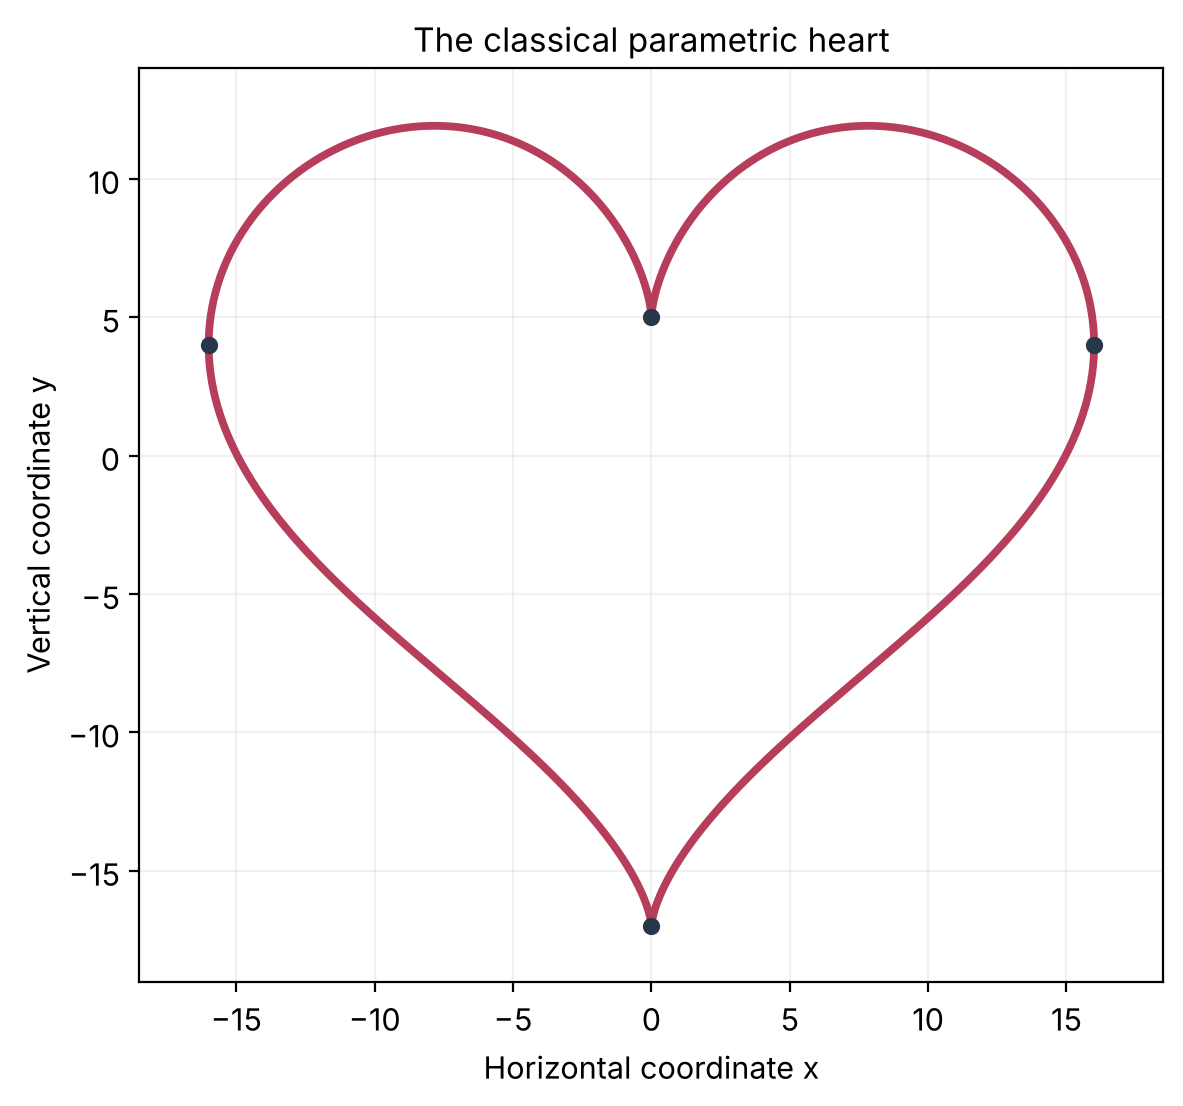

In [6]:
# Create a square drawing area so the two coordinate directions are comparable.
fig, ax = plt.subplots(figsize=(5.8, 5.8), layout="constrained")
# Draw the full parametric heart as a continuous curve.
ax.plot(heart_x, heart_y, color=colors["rose"], lw=2.8)
# Mark the four hand-checked landmarks to connect algebra with the plot.
ax.scatter(landmark_x, landmark_y, color=colors["ink"], s=27, zorder=3)
# Prevent the plotting window from stretching the outline.
ax.set_aspect("equal", adjustable="box")
# Leave a modest margin around the full curve.
ax.set(xlim=(-18.5, 18.5), ylim=(-19.0, 14.0), xlabel="Horizontal coordinate x", ylabel="Vertical coordinate y", title="The classical parametric heart")
# Keep the grid quiet so it does not compete with the curve.
ax.grid(alpha=0.17)
# Save and show the final plot.
finish_figure(fig, "02_classical_parametric_heart")


**Figure 2.** The landmark markers provide a visual check. Equal axis scaling preserves the intended shape; changing the figure's height alone must not change the geometry.


### Package the formula in a function and check symmetry

A function makes the formula reusable at different resolutions. Because sine changes sign under $t\mapsto2\pi-t$ while the cosine terms do not, the curve should be symmetric about the vertical axis. This is a stronger numerical test than inspecting one picture.


In [7]:
# Define a reusable function accepting a number or an array of parameters.
def parametric_heart(t):
    # Document what the function returns and the dimensionless coordinate convention.
    '''Return x(t), y(t) for the classical dimensionless heart.'''
    # Convert input to a NumPy array to support both scalar and vector evaluation.
    t = np.asarray(t, dtype=float)
    # Compute the horizontal coordinate from the sine term.
    x = 16.0 * np.sin(t)**3
    # Compute the vertical coordinate from the four cosine terms.
    y = 13.0 * np.cos(t) - 5.0 * np.cos(2.0 * t) - 2.0 * np.cos(3.0 * t) - np.cos(4.0 * t)
    # Return the two arrays with matching shapes.
    return x, y
# Evaluate the reusable function on the original sample.
check_x, check_y = parametric_heart(heart_t)
# Verify that rewriting the formula did not alter its values.
assert np.allclose(check_x, heart_x) and np.allclose(check_y, heart_y)
# Verify the expected left-right reflection in reversed samples.
assert np.allclose(check_x, -check_x[::-1], atol=1e-12)
# Verify that reflected sample pairs have the same vertical coordinate.
assert np.allclose(check_y, check_y[::-1], atol=1e-12)


### How many points are enough?

Matplotlib draws straight segments between computed coordinates. At very low resolution those segments reveal themselves, especially near tight turns. We quantify one simple approximation error: compare the *true formula at the middle of each parameter interval* with the midpoint of its straight chord. This is a diagnostic for this sampling scheme, not a proof of the exact maximum geometric error.


In [8]:
# Define a midpoint diagnostic for n equal parameter intervals.
def midpoint_error(n):
    # Document that the result is a maximum distance in coordinate units.
    '''Measure the largest formula-to-chord midpoint distance.'''
    # Include both endpoints so there are exactly n intervals.
    t_nodes = np.linspace(0.0, 2.0 * np.pi, n + 1)
    # Evaluate the curve at the ends of every interval.
    x_nodes, y_nodes = parametric_heart(t_nodes)
    # Find the midpoint parameter inside each interval.
    t_mid = 0.5 * (t_nodes[:-1] + t_nodes[1:])
    # Evaluate the actual curve formula at those midpoint parameters.
    x_true, y_true = parametric_heart(t_mid)
    # Approximate the same positions by the midpoints of straight chords.
    x_chord = 0.5 * (x_nodes[:-1] + x_nodes[1:])
    # Repeat the chord midpoint calculation vertically.
    y_chord = 0.5 * (y_nodes[:-1] + y_nodes[1:])
    # Return the largest Euclidean distance between true and chord midpoints.
    return np.max(np.hypot(x_true - x_chord, y_true - y_chord))
# Select several increasing numbers of intervals.
sample_sizes = [16, 32, 64, 128]
# Calculate one error estimate for each sampling choice.
sample_errors = [midpoint_error(n) for n in sample_sizes]
# Print results in the same order as the tested sample sizes.
for n, error in zip(sample_sizes, sample_errors):
    # Express the diagnostic in dimensionless coordinate units.
    print(f"{n:3d} segments: midpoint discrepancy {error:.4f}")
# Check that refinement improves this particular diagnostic.
assert all(b < a for a, b in zip(sample_errors[:-1], sample_errors[1:]))


 16 segments: midpoint discrepancy 0.8739
 32 segments: midpoint discrepancy 0.2290
 64 segments: midpoint discrepancy 0.0580
128 segments: midpoint discrepancy 0.0145


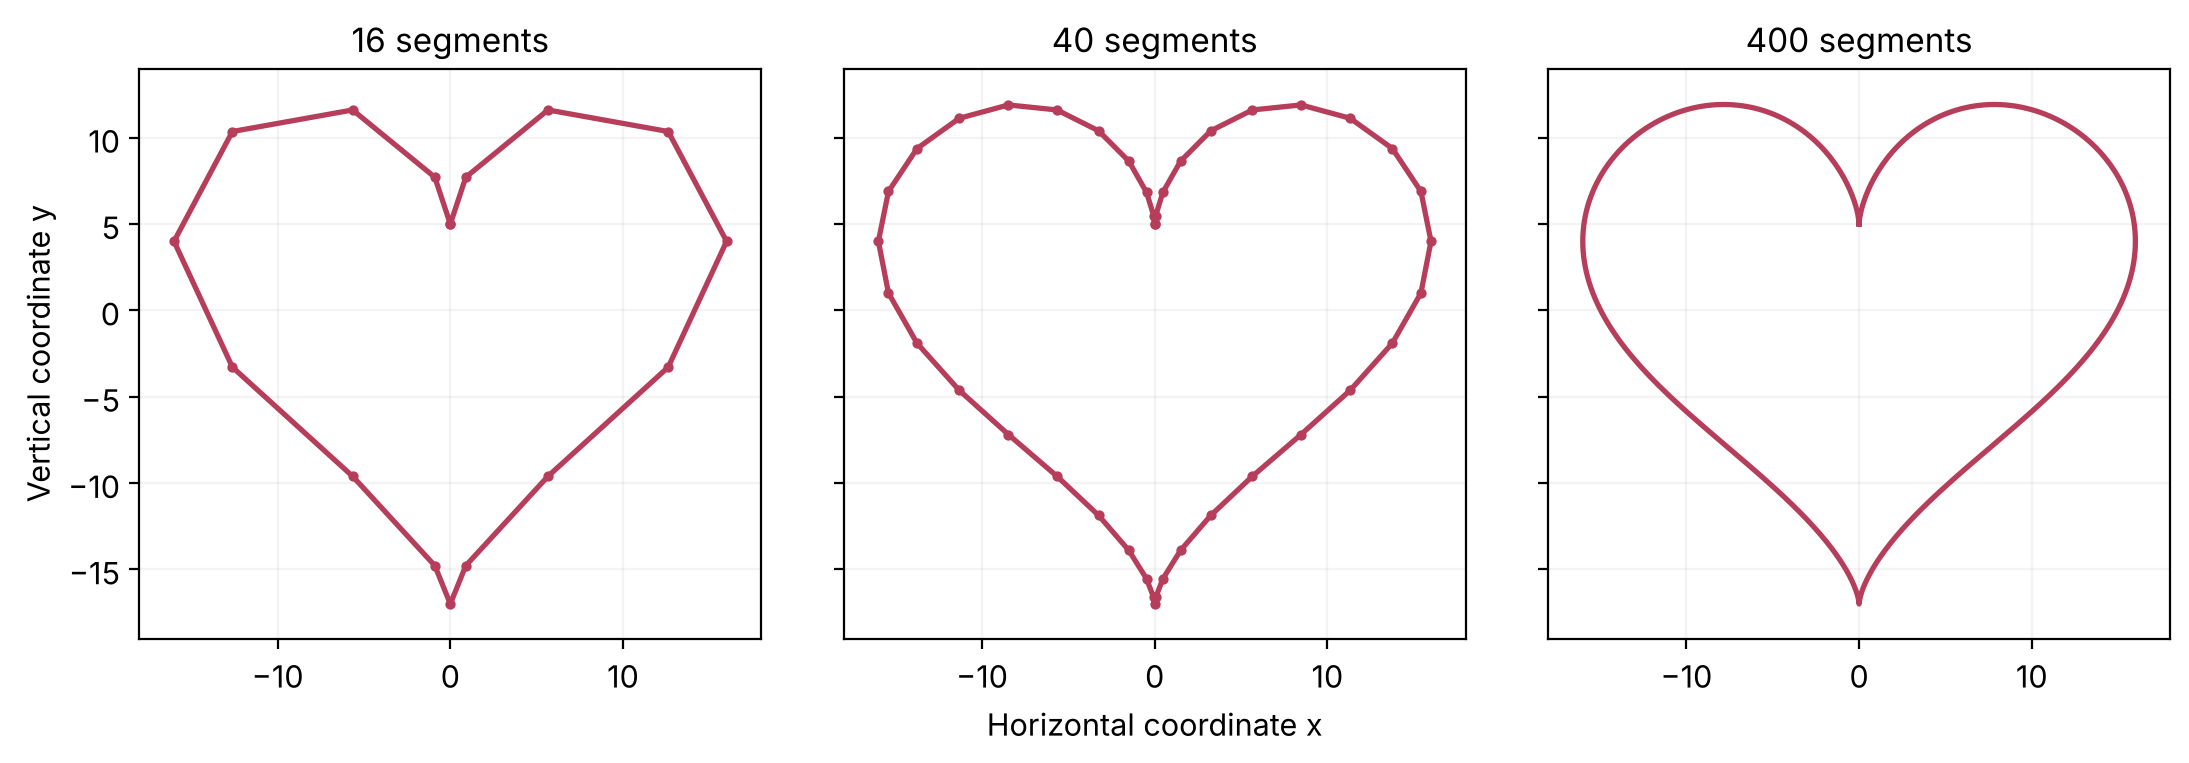

In [9]:
# Compare a coarse, medium, and fine sampling in matching panels.
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.7), sharex=True, sharey=True, layout="constrained")
# Test three visible resolutions without changing the underlying equation.
for ax, n in zip(axes, [16, 40, 400]):
    # Generate the exact same parameter interval with n straight segments.
    t_nodes = np.linspace(0.0, 2.0 * np.pi, n + 1)
    # Evaluate coordinates at the chosen nodes.
    x_nodes, y_nodes = parametric_heart(t_nodes)
    # Draw lines and show only the sparse nodes when the markers remain legible.
    ax.plot(x_nodes, y_nodes, color=colors["rose"], lw=1.9, marker="o" if n <= 40 else None, markersize=2.7)
    # Preserve geometry independently in every panel.
    ax.set_aspect("equal", adjustable="box")
    # Give each resolution a short title and light reference grid.
    ax.set(title=f"{n} segments", xlim=(-18, 18), ylim=(-19, 14))
    # Keep grid lines subtle behind the sample path.
    ax.grid(alpha=0.14)
# Label the first vertical axis because panels share it.
axes[0].set_ylabel("Vertical coordinate y")
# Label the common horizontal direction on the central panel.
axes[1].set_xlabel("Horizontal coordinate x")
# Export the comparison as one figure.
finish_figure(fig, "03_sampling_resolution")


**Figure 3.** The formula is unchanged. More sample points reduce visible polygon corners and the midpoint discrepancy. A smooth screen image alone does not tell us the exact error everywhere.


## 3. Transform a curve into a design

A translation moves a coordinate by adding an offset; scaling multiplies it. Separate horizontal and vertical scale factors can intentionally reshape a heart. Keep the axes equal while plotting: that lets us distinguish a change in the *data* from distortion by the plotting window.


In [10]:
# Define a reusable scale-and-translate transformation.
def transform_curve(x, y, scale_x=1.0, scale_y=1.0, shift_x=0.0, shift_y=0.0):
    # Explain the order: first scale the original shape, then move it.
    '''Scale coordinates independently, then translate them.'''
    # Scale and offset each horizontal coordinate.
    new_x = scale_x * np.asarray(x) + shift_x
    # Scale and offset each vertical coordinate.
    new_y = scale_y * np.asarray(y) + shift_y
    # Return transformed arrays without changing the input arrays.
    return new_x, new_y
# Create a smaller copy shifted to the right.
small_x, small_y = transform_curve(heart_x, heart_y, scale_x=0.55, scale_y=0.55, shift_x=27.0)
# Create a taller copy shifted to the left.
tall_x, tall_y = transform_curve(heart_x, heart_y, scale_x=0.65, scale_y=0.95, shift_x=-28.0)
# Check that an unchanged transformation reproduces the original arrays.
identity_x, identity_y = transform_curve(heart_x, heart_y)
# Assert both coordinates are unaffected by the identity choice.
assert np.array_equal(identity_x, heart_x) and np.array_equal(identity_y, heart_y)


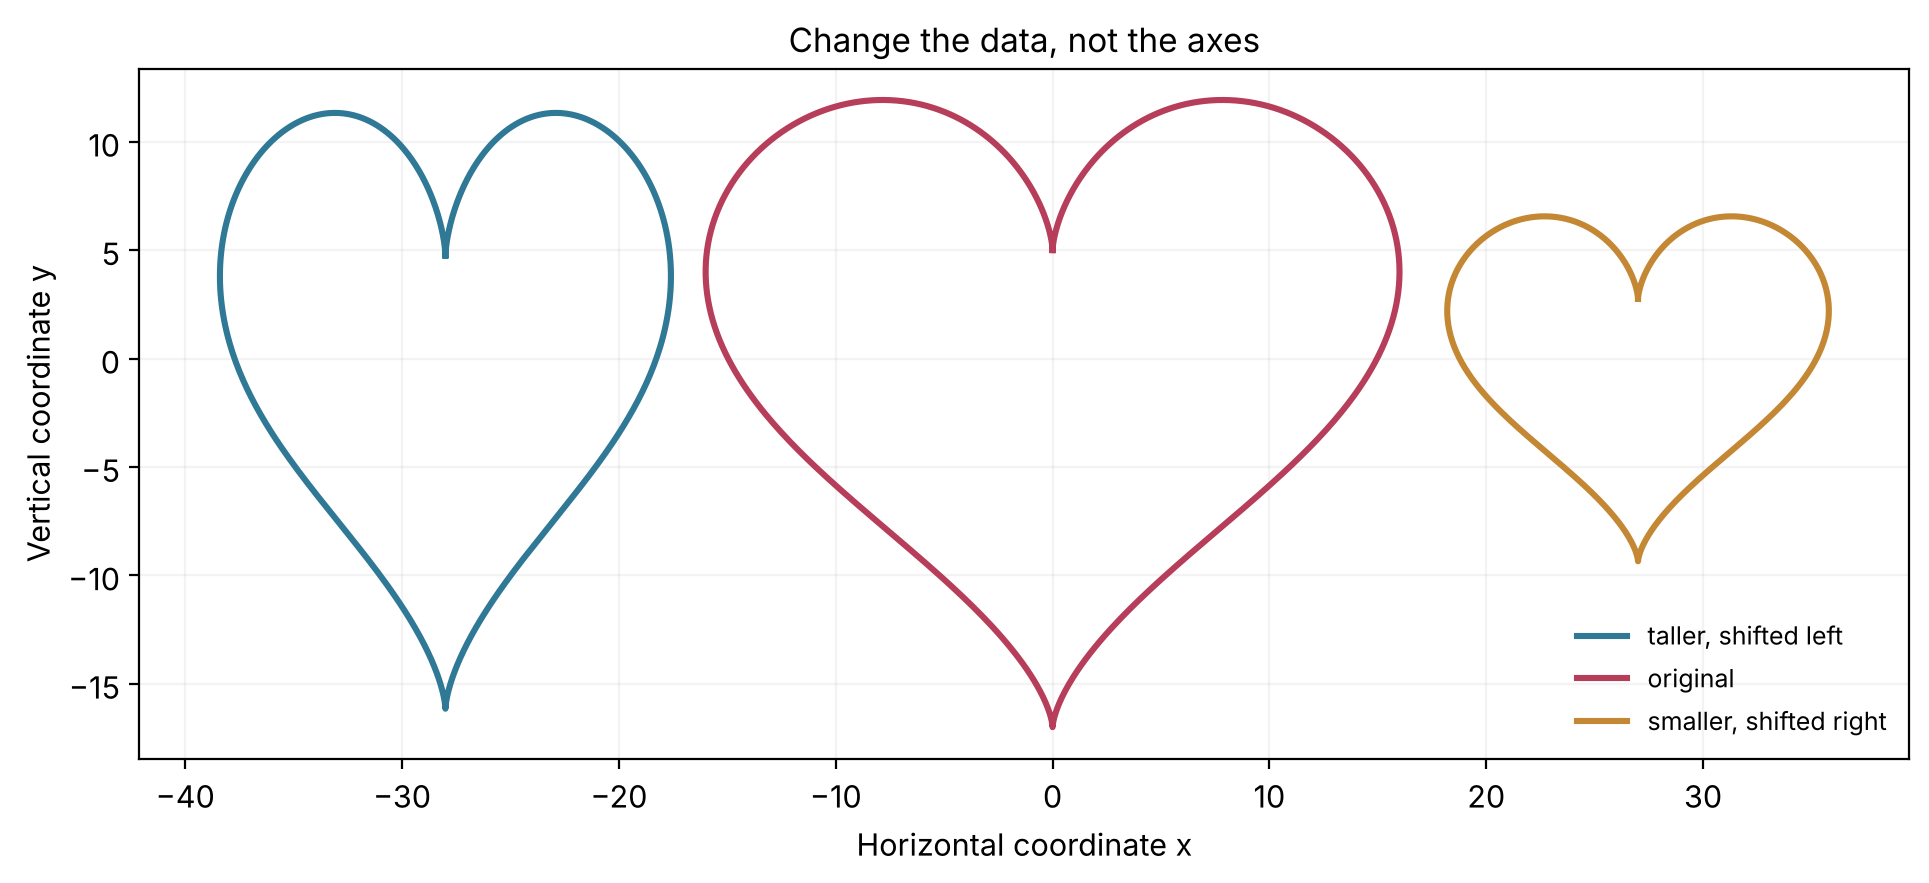

In [11]:
# Prepare one coordinate system containing three related shapes.
fig, ax = plt.subplots(figsize=(10.0, 4.3), layout="constrained")
# Draw the deliberately taller transformed design on the left.
ax.plot(tall_x, tall_y, color=colors["blue"], lw=2.2, label="taller, shifted left")
# Draw the original formula in the center.
ax.plot(heart_x, heart_y, color=colors["rose"], lw=2.2, label="original")
# Draw the uniformly scaled copy on the right.
ax.plot(small_x, small_y, color=colors["gold"], lw=2.2, label="smaller, shifted right")
# Preserve one-to-one scaling between the two coordinate directions.
ax.set_aspect("equal", adjustable="box")
# Give the panel clear labels and a descriptive title.
ax.set(xlabel="Horizontal coordinate x", ylabel="Vertical coordinate y", title="Change the data, not the axes")
# Explain color meanings without covering the paths.
ax.legend(loc="lower right", fontsize=9, frameon=False)
# Add restrained grid lines for comparing offsets.
ax.grid(alpha=0.15)
# Save both export formats and display the comparison.
finish_figure(fig, "04_curve_transformations")


**Figure 4.** The same function produces three designs. Horizontal and vertical scaling changed the left heart's proportions; the right heart only changed size and position.


## 4. A polar heart: radius depends on direction

**Polar coordinates** describe a point by an angle $\theta$ and a radius $r$. Convert to Cartesian coordinates with $x=r\cos\theta$ and $y=r\sin\theta$. MathWorld's rotated cardioid uses $r(\theta)=1-\sin\theta$. At $\theta=\pi/2$, its radius is zero, making a cusp at the origin; at $3\pi/2$, its radius is two. Its silhouette differs from the familiar two-lobed icon, illustrating that “heart-shaped” includes a family of curves.


In [12]:
# Sample a complete angular revolution for the polar curve.
polar_theta = np.linspace(0.0, 2.0 * np.pi, 801)
# Evaluate the cardioid's nonnegative distance from the origin.
cardioid_r = 1.0 - np.sin(polar_theta)
# Convert radius and angle into horizontal positions.
cardioid_x = cardioid_r * np.cos(polar_theta)
# Convert the same radius and angle into vertical positions.
cardioid_y = cardioid_r * np.sin(polar_theta)
# Verify that the radius never becomes negative for this formula.
assert np.min(cardioid_r) >= -1e-14
# Verify the Cartesian coordinates reconstruct the squared polar radius.
assert np.allclose(cardioid_x**2 + cardioid_y**2, cardioid_r**2, atol=1e-12)


In [13]:
# Calculate the two landmark radii directly from their defining angles.
cusp_radius = 1.0 - np.sin(np.pi / 2.0)
# Calculate the radius in the opposite direction.
opposite_radius = 1.0 - np.sin(3.0 * np.pi / 2.0)
# Check the hand predictions for the cusp and the farthest downward point.
assert np.isclose(cusp_radius, 0.0) and np.isclose(opposite_radius, 2.0)
# Report the two values with their role in the drawing.
print(f"At theta=pi/2, r={cusp_radius:.1f}; at theta=3pi/2, r={opposite_radius:.1f}.")


At theta=pi/2, r=0.0; at theta=3pi/2, r=2.0.


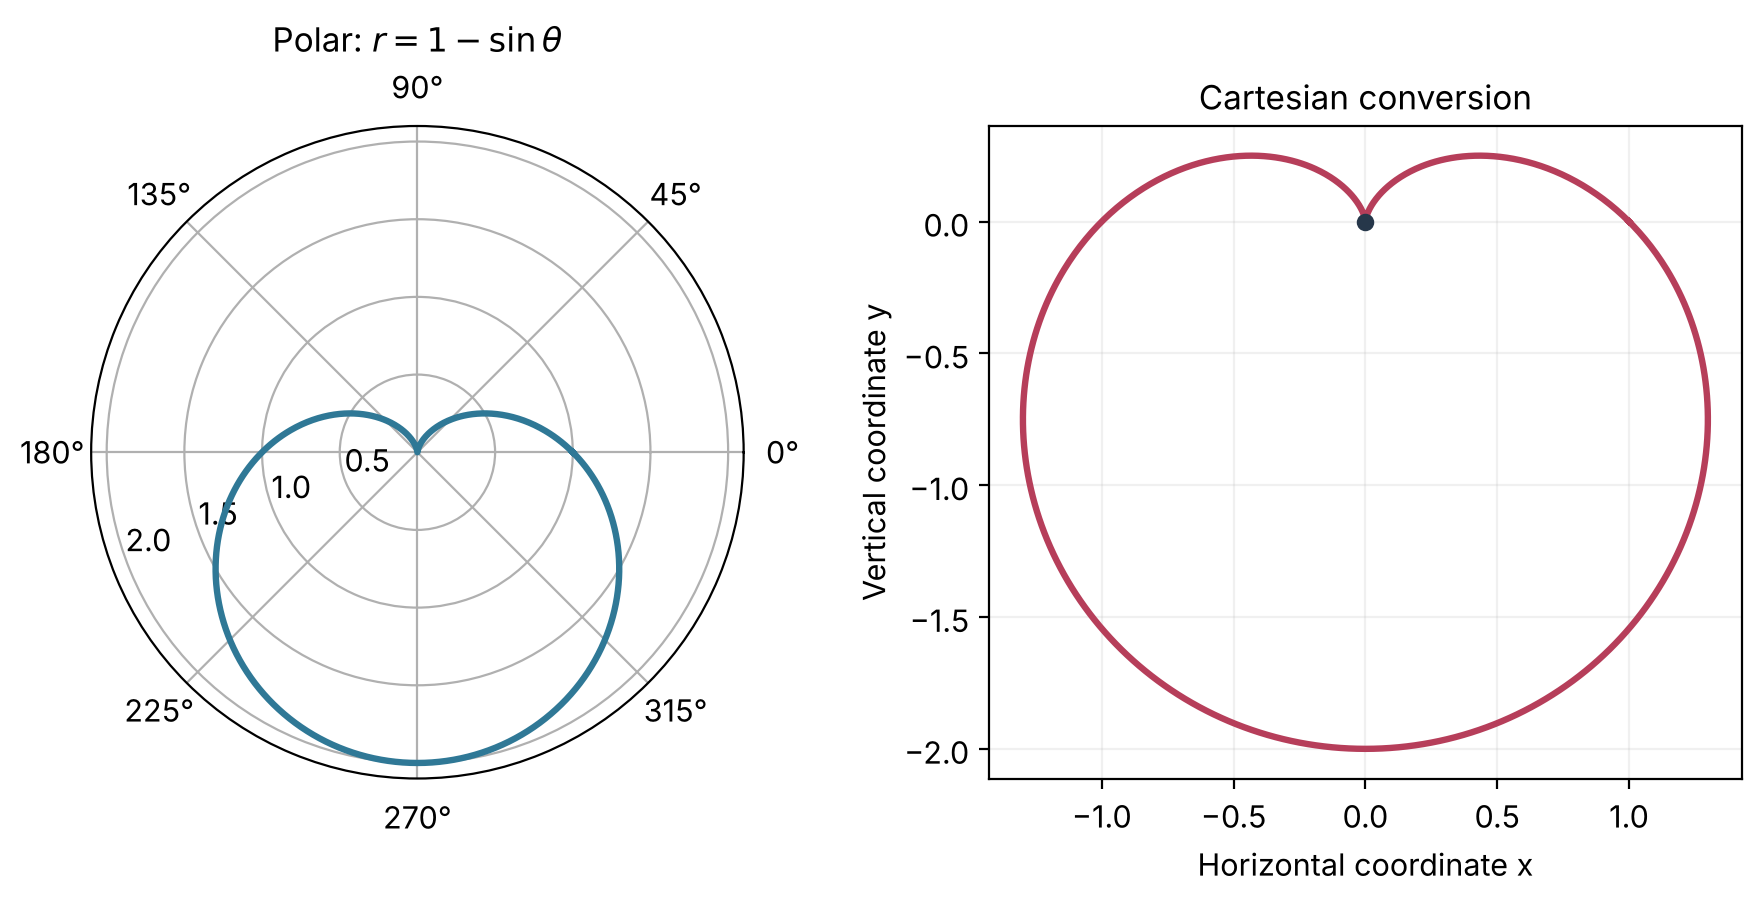

In [14]:
# Create polar and Cartesian panels for the same sampled points.
fig = plt.figure(figsize=(9.0, 4.4), layout="constrained")
# Add a polar axes on the left using angle and radius directly.
ax_polar = fig.add_subplot(1, 2, 1, projection="polar")
# Add ordinary x-y axes on the right for the converted coordinates.
ax_xy = fig.add_subplot(1, 2, 2)
# Draw radius as a function of direction in polar axes.
ax_polar.plot(polar_theta, cardioid_r, color=colors["blue"], lw=2.3)
# Label the polar representation rather than relying on an unexplained shape.
ax_polar.set_title(r"Polar: $r=1-\sin\theta$")
# Keep only a few radial labels so the polar panel stays readable.
ax_polar.set_rticks([0.5, 1.0, 1.5, 2.0])
# Place radius labels away from the densest lower portion of the outline.
ax_polar.set_rlabel_position(200)
# Draw the mathematically identical Cartesian coordinate pairs.
ax_xy.plot(cardioid_x, cardioid_y, color=colors["rose"], lw=2.3)
# Mark the cusp where the radius vanishes.
ax_xy.scatter([0.0], [0.0], color=colors["ink"], s=28, zorder=3)
# Preserve geometry and identify the converted view.
ax_xy.set(aspect="equal", xlabel="Horizontal coordinate x", ylabel="Vertical coordinate y", title="Cartesian conversion")
# Use light grids in both views for reading angles and coordinates.
ax_xy.grid(alpha=0.18)
# Export and show the two-panel explanation.
finish_figure(fig, "05_polar_cardioid")


**Figure 5.** Both panels show the same radius rule. The right panel uses $x=r\cos\theta$ and $y=r\sin\theta$; the dot is the zero-radius cusp.


What happens if we use $r=1-a\sin\theta$ and change $a$ from $0.5$ toward $1$? We keep $0\le a\le1$ so the radius stays nonnegative. This is a controlled design experiment: change one number, hold the sample angles and axes fixed.


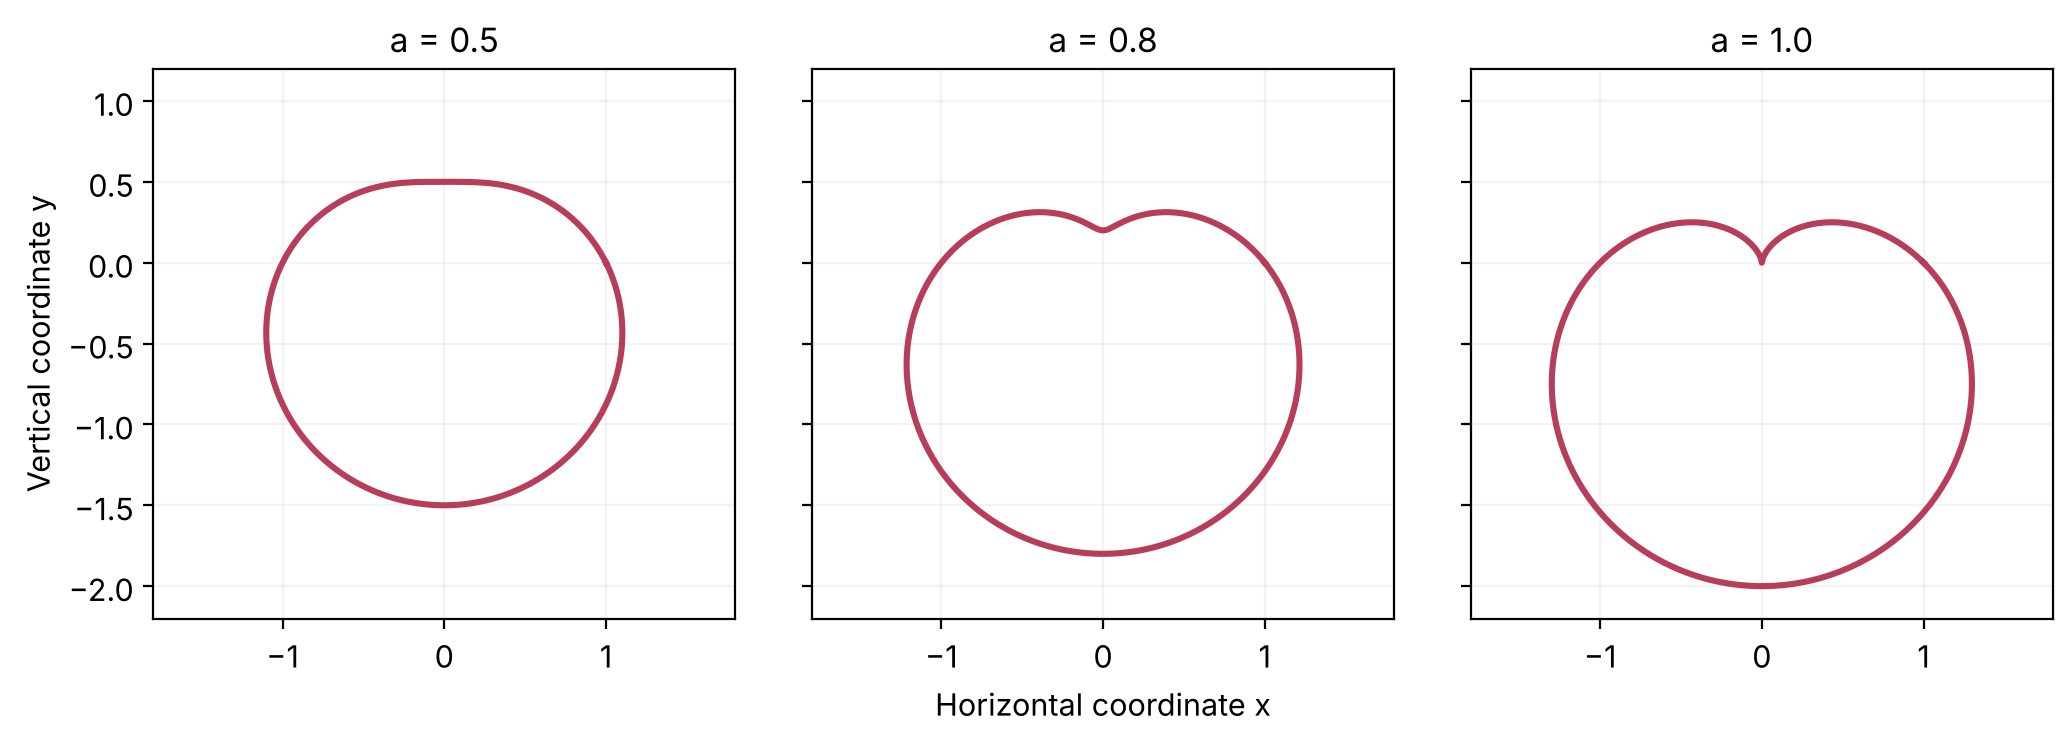

In [15]:
# Create matching axes for three choices of the radial parameter.
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.6), sharex=True, sharey=True, layout="constrained")
# Reuse the exact same angle array for every design choice.
for ax, a in zip(axes, [0.5, 0.8, 1.0]):
    # Apply the one-parameter radial rule at every angle.
    radius = 1.0 - a * np.sin(polar_theta)
    # Convert this variant to the same Cartesian coordinate system.
    x_variant = radius * np.cos(polar_theta)
    # Compute its vertical coordinates from the same radius.
    y_variant = radius * np.sin(polar_theta)
    # Plot one variation without changing the axis limits.
    ax.plot(x_variant, y_variant, color=colors["rose"], lw=2.2)
    # Keep equal units and the same view across panels.
    ax.set(aspect="equal", xlim=(-1.8, 1.8), ylim=(-2.2, 1.2), title=f"a = {a:.1f}")
    # Use a faint common reference grid.
    ax.grid(alpha=0.15)
# Label the shared coordinate directions in the outer panels.
axes[0].set_ylabel("Vertical coordinate y")
# Place the horizontal label under the center panel.
axes[1].set_xlabel("Horizontal coordinate x")
# Save the controlled comparison and show it.
finish_figure(fig, "06_polar_parameter_variations")


**Figure 6.** At $a=1$ the top radius reaches zero. For smaller $a$ there is no zero-radius cusp. We should not claim the other shapes are the same curve merely because each looks rounded.


## 5. An implicit heart: plot the zero set

An **implicit equation** gives a condition on $x$ and $y$, rather than a direct recipe for $x(t)$ and $y(t)$. MathWorld's algebraic example is
$$F(x,y)=(x^2+y^2-1)^3-x^2y^3=0.$$
On a rectangular grid, evaluate $F$ at each coordinate pair and ask Matplotlib to trace where it changes through zero. This is a numerical *contour*, so its sampled vertices only approximate the exact equation. **Predict:** are $(0,1)$ and $(0,-1)$ on the curve? Why must it be symmetric about the vertical axis?


In [16]:
# Define the scalar expression whose zero contour forms the algebraic heart.
def implicit_heart_value(x, y):
    # Explain that arrays are accepted through NumPy broadcasting.
    '''Evaluate F(x,y)=(x²+y²-1)³-x²y³.'''
    # Return one value for each matching or broadcast coordinate pair.
    return (x**2 + y**2 - 1.0)**3 - x**2 * y**3
# Evaluate the function at two hand-checkable axis intercepts.
axis_values = implicit_heart_value(np.array([0.0, 0.0]), np.array([1.0, -1.0]))
# Require both points to satisfy the exact zero condition.
assert np.allclose(axis_values, 0.0, atol=1e-14)
# Evaluate a nontrivial point and its reflection across the vertical axis.
mirror_left = implicit_heart_value(-0.7, 0.6)
# Evaluate the corresponding point on the right.
mirror_right = implicit_heart_value(0.7, 0.6)
# Check symmetry algebraically through the computed values.
assert np.isclose(mirror_left, mirror_right)


In [17]:
# Make horizontal coordinates covering the entire expected outline.
grid_x = np.linspace(-1.5, 1.5, 451)
# Make vertical coordinates with room above and below the curve.
grid_y = np.linspace(-1.4, 1.7, 451)
# Expand one-dimensional axes into coordinate matrices.
X, Y = np.meshgrid(grid_x, grid_y)
# Evaluate the implicit equation at every grid intersection.
F = implicit_heart_value(X, Y)
# Check that the two-dimensional grid and field have matching shapes.
assert F.shape == X.shape == Y.shape
# Confirm the field is finite before requesting a contour.
assert np.all(np.isfinite(F))


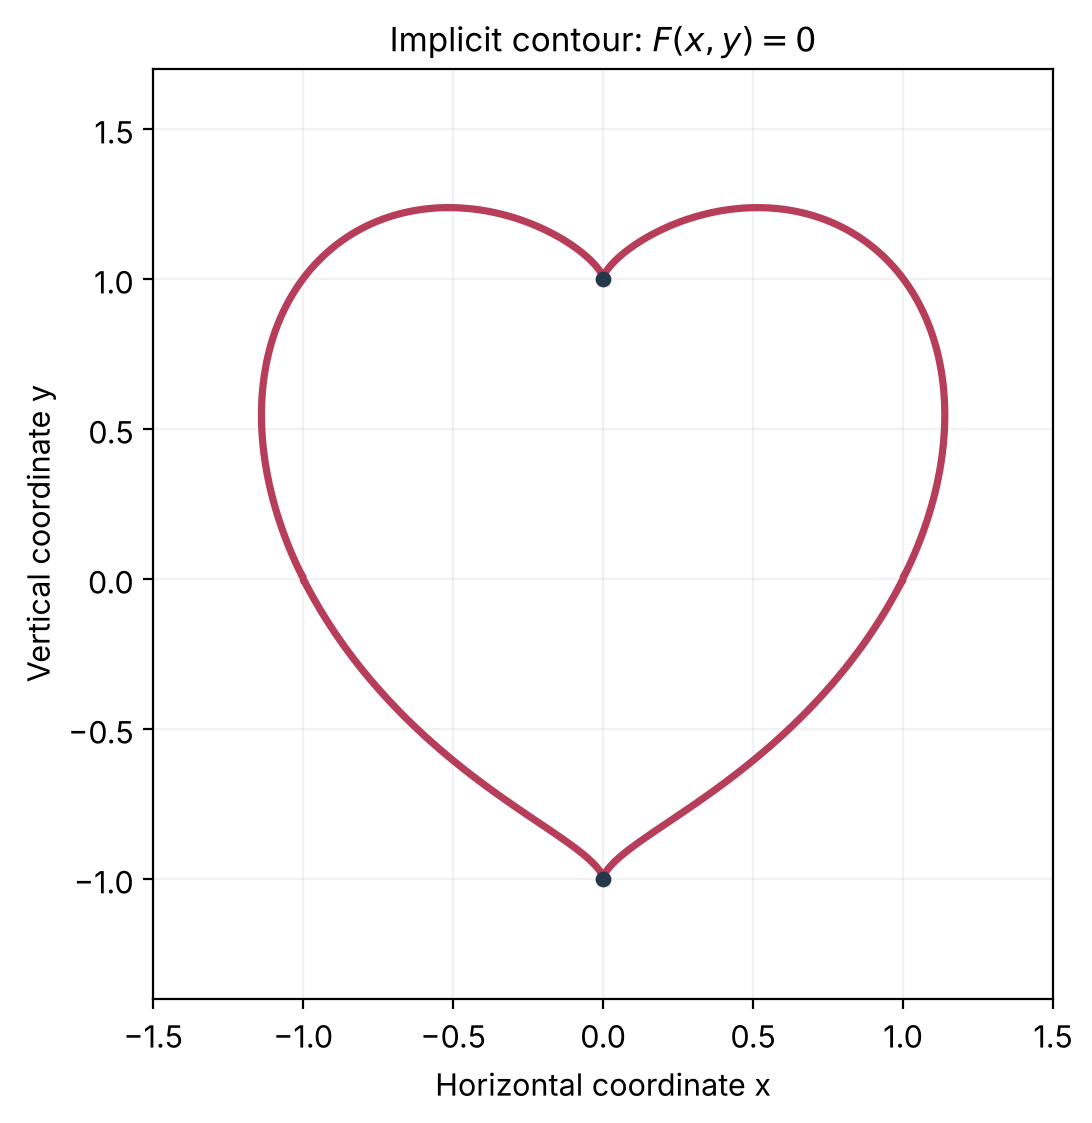

In [18]:
# Create a square coordinate view for the implicit zero contour.
fig, ax = plt.subplots(figsize=(5.7, 5.5), layout="constrained")
# Trace only F=0 rather than coloring all scalar field values.
ax.contour(X, Y, F, levels=[0.0], colors=[colors["rose"]], linewidths=2.6)
# Mark the two exact intercepts used in the independent check.
ax.scatter([0.0, 0.0], [1.0, -1.0], color=colors["ink"], s=22, zorder=3)
# Keep the coordinate geometry and bounds explicit.
ax.set(aspect="equal", xlim=(-1.5, 1.5), ylim=(-1.4, 1.7), xlabel="Horizontal coordinate x", ylabel="Vertical coordinate y", title=r"Implicit contour: $F(x,y)=0$")
# Use a light grid to expose the intercepts without distracting from the curve.
ax.grid(alpha=0.17)
# Export the original Python contour and show it.
finish_figure(fig, "07_implicit_algebraic_heart")


**Figure 7.** The contour algorithm draws an approximate zero set. Unlike the parametric example, we did not calculate points along the curve in a known order.


Grid resolution matters for contours too. The next figure uses the same formula and limits with a coarse grid and a finer grid. Refinement improves the visible outline, although a picture by itself does not prove exact convergence at a singular point.


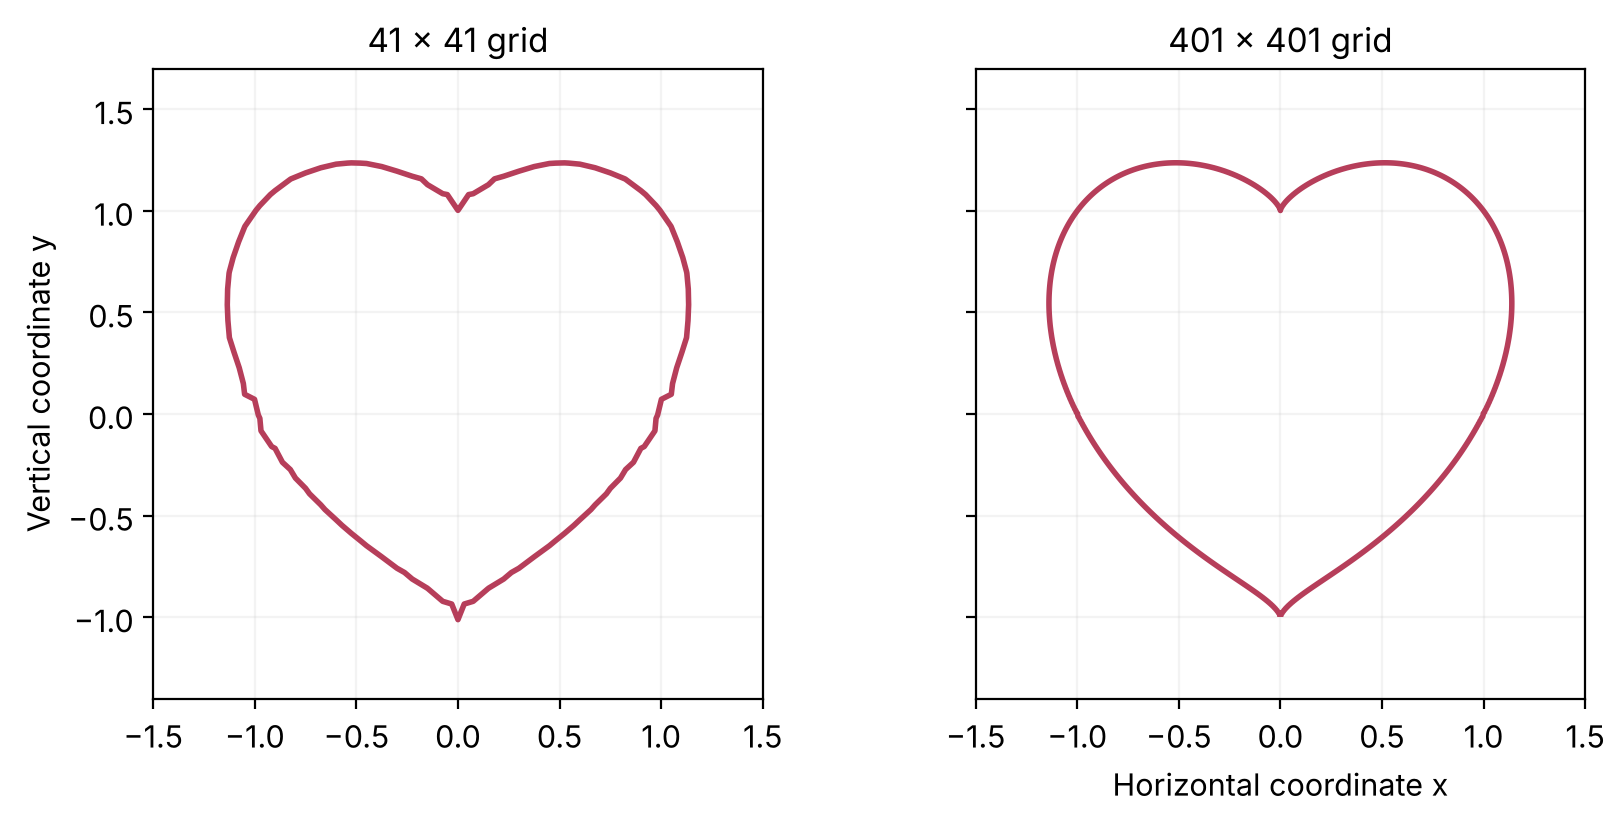

In [19]:
# Make two panels with matching extents to isolate grid resolution.
fig, axes = plt.subplots(1, 2, figsize=(8.4, 4.0), sharex=True, sharey=True, layout="constrained")
# Test a deliberately coarse grid and a substantially finer grid.
for ax, count in zip(axes, [41, 401]):
    # Create the horizontal samples with this grid count.
    local_x = np.linspace(-1.5, 1.5, count)
    # Create the vertical samples over the same geometric extent.
    local_y = np.linspace(-1.4, 1.7, count)
    # Build all coordinate pairs for the implicit evaluation.
    local_X, local_Y = np.meshgrid(local_x, local_y)
    # Evaluate F on this resolution alone.
    local_F = implicit_heart_value(local_X, local_Y)
    # Trace the zero contour of the same mathematical function.
    ax.contour(local_X, local_Y, local_F, levels=[0.0], colors=[colors["rose"]], linewidths=2.0)
    # Use equal scales and identical bounds for a fair visual comparison.
    ax.set(aspect="equal", xlim=(-1.5, 1.5), ylim=(-1.4, 1.7), title=f"{count} × {count} grid")
    # Show a restrained reference grid beneath both contours.
    ax.grid(alpha=0.15)
# Label the two coordinate directions once for the shared panels.
axes[0].set_ylabel("Vertical coordinate y")
# Add the shared horizontal coordinate label to the right panel.
axes[1].set_xlabel("Horizontal coordinate x")
# Save and display the resolution comparison.
finish_figure(fig, "08_implicit_grid_resolution")


**Figure 8.** A coarse contour can distort the notch or tip. If a numerical drawing changes noticeably when you refine the grid, report the resolution rather than presenting the first image as exact.


## 6. Make a heart by reflecting half an ellipse

Nick described the visually pronounced equation $x^2+y^2-|x|y=1$. For $x\ge0$, this is the tilted ellipse $x^2+y^2-xy=1$; the absolute value mirrors that right half across the vertical axis. Wu later expressed the same outline in polar form:
$$r(\theta)=\frac{1}{\sqrt{1-|\cos\theta|\sin\theta}},\qquad
x=r\cos\theta,\quad y=r\sin\theta.$$
This follows by inserting the polar conversion into the implicit equation and taking the positive radius. Since $|\cos\theta\sin\theta|\le1/2$, the square-root denominator is safely positive. The polar curve is a direct way to sample the outline; the implicit formula supplies an independent residual check.


In [20]:
# Define the positive-radius polar representation of the reflected ellipse.
def reflected_ellipse_polar(theta):
    # State that the function returns both Cartesian coordinates and the denominator.
    '''Return x, y, denominator for the reflected-ellipse heart.'''
    # Convert input angles into a NumPy array.
    theta = np.asarray(theta, dtype=float)
    # Compute the dimensionless expression under the square root.
    denominator = 1.0 - np.abs(np.cos(theta)) * np.sin(theta)
    # Convert the positive radius into horizontal positions.
    x = np.cos(theta) / np.sqrt(denominator)
    # Convert the same radius into vertical positions.
    y = np.sin(theta) / np.sqrt(denominator)
    # Return coordinates and a useful domain diagnostic.
    return x, y, denominator
# Use enough angles to make the reflected curve smooth.
reflect_theta = np.linspace(0.0, 2.0 * np.pi, 1201)
# Evaluate all sampled reflected-ellipse positions.
reflect_x, reflect_y, reflect_denominator = reflected_ellipse_polar(reflect_theta)
# Check the analytic denominator bound before interpreting the square root.
assert reflect_denominator.min() >= 0.5 - 1e-12
# Compute the original implicit equation at the sampled polar positions.
reflect_residual = reflect_x**2 + reflect_y**2 - np.abs(reflect_x) * reflect_y - 1.0
# Verify the conversion to Cartesian coordinates independently.
assert np.max(np.abs(reflect_residual)) < 1e-12
# Print the largest residual so students see the size of floating-point error.
print(f"Maximum reflected-heart equation residual: {np.max(np.abs(reflect_residual)):.2e}")


Maximum reflected-heart equation residual: 6.66e-16


We can also solve the right-half ellipse as a quadratic equation in $y$:
$$y_\pm(x)=\frac{x\pm\sqrt{4-3x^2}}{2},\qquad 0\le x\le\frac{2}{\sqrt3}.$$
Plot both branches for $x\ge0$ and their mirror images for $x\le0$. The range on $x$ is essential: beyond it, the square root has a negative input and no real curve point exists. **Predict:** will the two independent plotting approaches coincide?


In [21]:
# Sample only the real domain of the right-hand ellipse branches.
right_x = np.linspace(0.0, 2.0 / np.sqrt(3.0), 601)
# Evaluate the discriminant, which must be nonnegative for real y values.
discriminant = 4.0 - 3.0 * right_x**2
# Clip tiny negative round-off at the endpoint before taking a square root.
branch_root = np.sqrt(np.maximum(discriminant, 0.0))
# Calculate the upper solution of the quadratic equation.
right_upper = 0.5 * (right_x + branch_root)
# Calculate its lower solution using the opposite sign.
right_lower = 0.5 * (right_x - branch_root)
# Verify the sampled branches satisfy the right-hand ellipse equation.
assert np.max(np.abs(right_x**2 + right_upper**2 - right_x * right_upper - 1.0)) < 1e-12
# Verify the lower branch independently against the same equation.
assert np.max(np.abs(right_x**2 + right_lower**2 - right_x * right_lower - 1.0)) < 1e-12


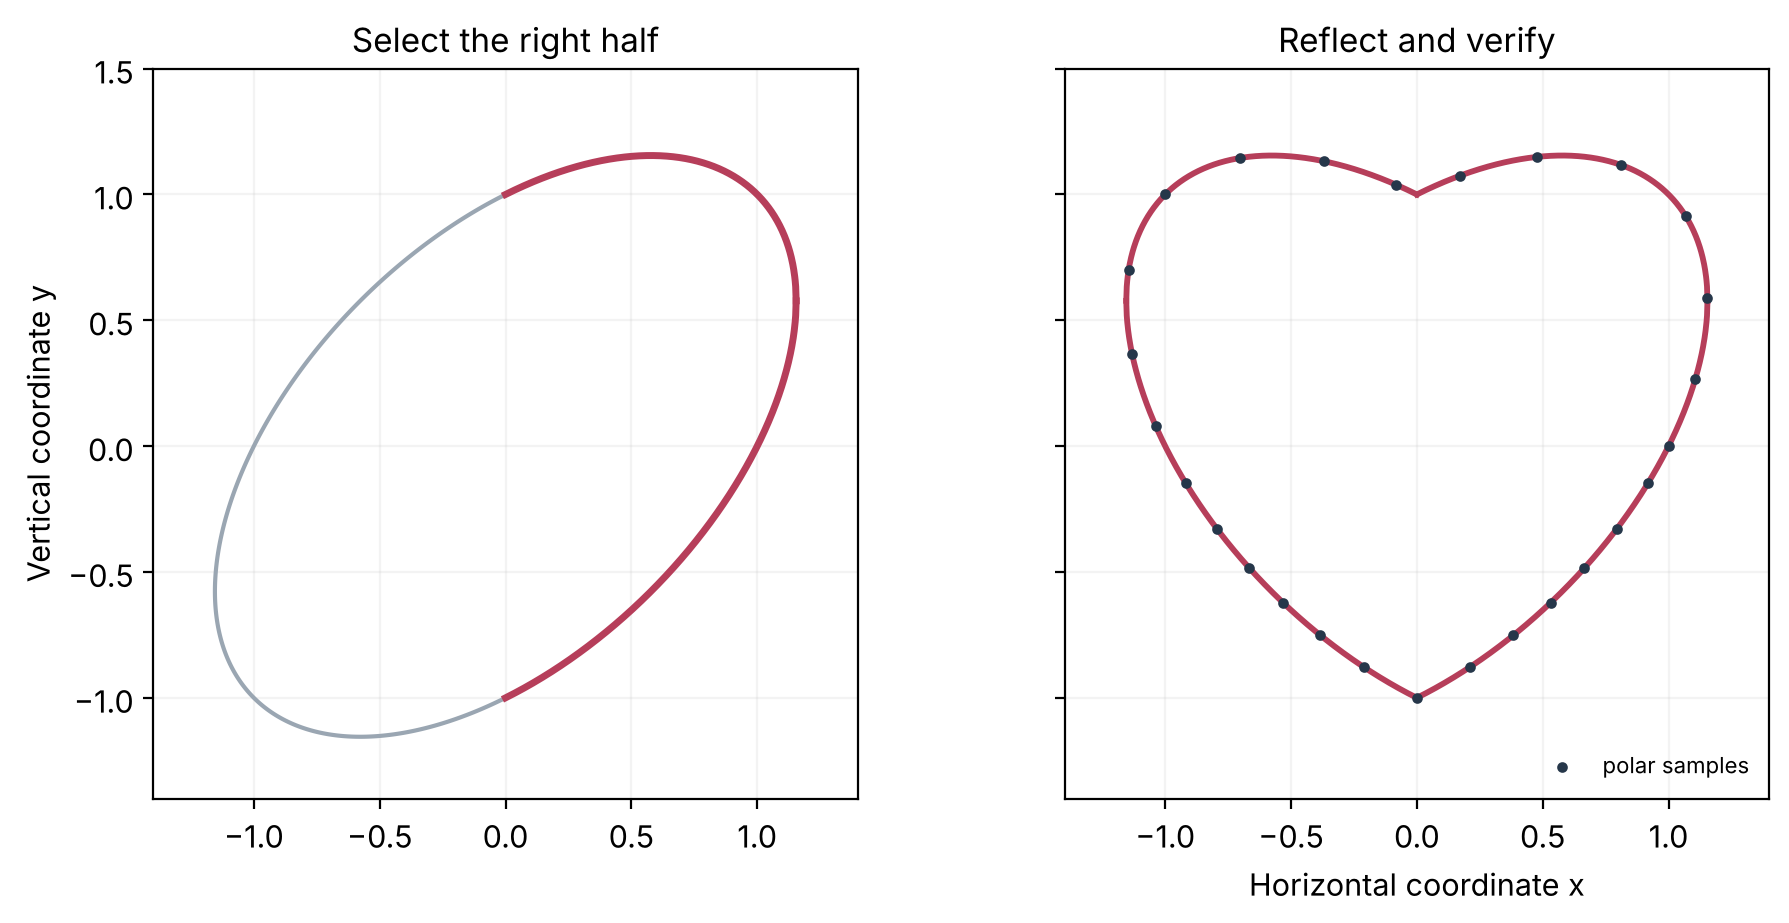

In [22]:
# Create two aligned panels to show construction and independent agreement.
fig, axes = plt.subplots(1, 2, figsize=(9.3, 4.5), sharex=True, sharey=True, layout="constrained")
# Draw the full tilted ellipse as context for taking its right half.
axes[0].contour(X, Y, X**2 + Y**2 - X * Y - 1.0, levels=[0.0], colors=[colors["gray"]], linewidths=1.5)
# Emphasize the upper right half selected for reflection.
axes[0].plot(right_x, right_upper, color=colors["rose"], lw=2.5)
# Emphasize the lower right half selected for reflection.
axes[0].plot(right_x, right_lower, color=colors["rose"], lw=2.5)
# Draw both explicitly calculated branches on the right.
axes[1].plot(right_x, right_upper, color=colors["rose"], lw=2.1)
# Add the lower right branch to close the right side.
axes[1].plot(right_x, right_lower, color=colors["rose"], lw=2.1)
# Reflect the upper branch across the vertical axis.
axes[1].plot(-right_x, right_upper, color=colors["rose"], lw=2.1)
# Reflect the lower branch across the vertical axis.
axes[1].plot(-right_x, right_lower, color=colors["rose"], lw=2.1)
# Overlay sparse independently sampled polar points for comparison.
axes[1].scatter(reflect_x[::45], reflect_y[::45], color=colors["ink"], s=8, zorder=3, label="polar samples")
# Set identical geometry, bounds, and grids in both panels.
for ax in axes:
    # Keep units equal so reflection is geometrically faithful.
    ax.set(aspect="equal", xlim=(-1.4, 1.4), ylim=(-1.4, 1.5))
    # Add light reference lines to expose the symmetry axis.
    ax.grid(alpha=0.15)
# Distinguish the original ellipse from the reconstructed heart.
axes[0].set(title="Select the right half", ylabel="Vertical coordinate y")
# Explain the polar markers in the reconstructed panel.
axes[1].set(title="Reflect and verify", xlabel="Horizontal coordinate x")
# Add a small marker key without covering the center notch.
axes[1].legend(loc="lower right", frameon=False, fontsize=8)
# Save and show both ways to construct this curve.
finish_figure(fig, "09_reflected_ellipse_heart")


**Figure 9.** Gray is the original tilted ellipse. Red is its selected right half and reflected left half. The dark polar samples sit on the red outline because the two equations describe the same curve.


## 7. A surprising area result from moving vertical slices

MathWorld also lists $x^2+[y-|x|^{2/3}]^2=1$. Solving for $y$ gives two branches
$$y_\pm(x)=|x|^{2/3}\pm\sqrt{1-x^2},\qquad -1\le x\le1.$$
At each horizontal position, the unit circle's upper and lower points are shifted **upward by the same amount** $|x|^{2/3}$. The shape changes, but the vertical slice length remains $y_+-y_-=2\sqrt{1-x^2}$. Consequently its enclosed area equals the unit circle's area, $\pi$. The slice argument works without evaluating an integral.


In [23]:
# Sample the real domain in which 1-x squared is nonnegative.
card_x = np.linspace(-1.0, 1.0, 1201)
# Compute the vertical shift shared by the upper and lower branches.
card_shift = np.abs(card_x)**(2.0 / 3.0)
# Compute the circle's nonnegative half-height at each x coordinate.
card_root = np.sqrt(np.maximum(1.0 - card_x**2, 0.0))
# Shift the circle's upper branch upward.
card_upper = card_shift + card_root
# Shift the circle's lower branch by exactly the same amount.
card_lower = card_shift - card_root
# Verify the upper coordinates satisfy the original implicit equation.
upper_residual = card_x**2 + (card_upper - card_shift)**2 - 1.0
# Verify the lower branch with the same residual calculation.
lower_residual = card_x**2 + (card_lower - card_shift)**2 - 1.0
# Require both residuals to be near floating-point precision.
assert max(np.max(np.abs(upper_residual)), np.max(np.abs(lower_residual))) < 1e-12
# Require left and right heights to mirror around x=0.
assert np.allclose(card_upper, card_upper[::-1]) and np.allclose(card_lower, card_lower[::-1])


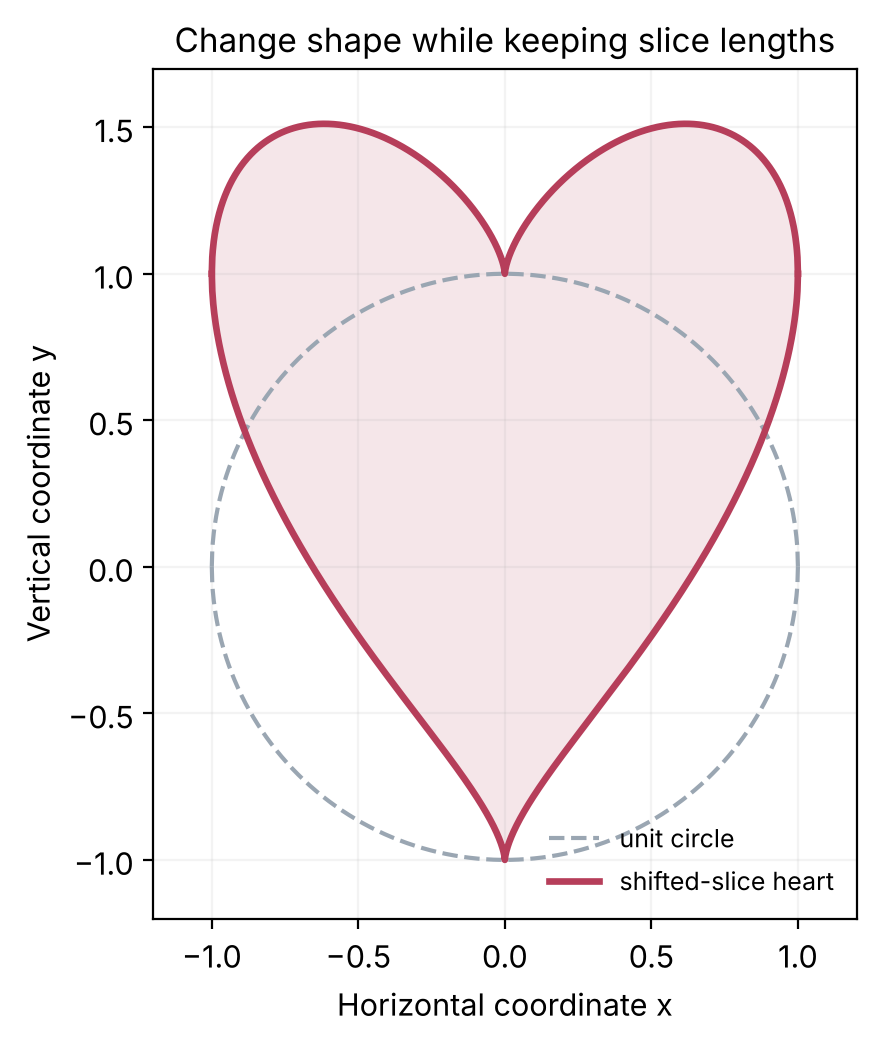

In [24]:
# Create a panel showing the original circle and its shifted heart.
fig, ax = plt.subplots(figsize=(6.0, 5.1), layout="constrained")
# Fill the new region lightly so the enclosed area is visible.
ax.fill_between(card_x, card_lower, card_upper, color=colors["rose"], alpha=0.13)
# Draw the old circle's upper semicircle as a dashed comparison.
ax.plot(card_x, card_root, color=colors["gray"], ls="--", lw=1.5, label="unit circle")
# Draw its lower semicircle with the same reference style.
ax.plot(card_x, -card_root, color=colors["gray"], ls="--", lw=1.5)
# Draw the shifted upper heart boundary prominently.
ax.plot(card_x, card_upper, color=colors["rose"], lw=2.4, label="shifted-slice heart")
# Draw the shifted lower heart boundary with matching style.
ax.plot(card_x, card_lower, color=colors["rose"], lw=2.4)
# Preserve geometric units and leave room for the upper lobes.
ax.set(aspect="equal", xlim=(-1.2, 1.2), ylim=(-1.2, 1.7), xlabel="Horizontal coordinate x", ylabel="Vertical coordinate y", title="Change shape while keeping slice lengths")
# Place a small legend away from the narrow central region.
ax.legend(loc="lower right", frameon=False, fontsize=9)
# Draw faint guides for reading the coordinate shift.
ax.grid(alpha=0.15)
# Save and display the original figure.
finish_figure(fig, "10_shifted_slice_heart")


**Figure 10.** A horizontal position keeps the circle's vertical slice length, although the slice is moved. This explains the equal enclosed areas.


### Check the area numerically

Approximate the area by vertical trapezoids. Each trapezoid uses the neighboring slice heights and their horizontal spacing. More samples should approach $\pi$. This is a numerical confirmation of the geometric slice argument, not a replacement for it.


In [25]:
# Define a transparent trapezoidal sum for an upper and lower boundary.
def slice_area(x, upper, lower):
    # Explain the algorithm's geometric interpretation.
    '''Approximate enclosed area using vertical trapezoids.'''
    # Compute the nonnegative vertical width at each x value.
    heights = np.asarray(upper) - np.asarray(lower)
    # Compute all horizontal distances between neighboring slices.
    widths = np.diff(x)
    # Sum the trapezoids built from neighboring slice heights.
    return np.sum(0.5 * (heights[:-1] + heights[1:]) * widths)
# Compute the area from the displayed 1201-point curve.
card_area = slice_area(card_x, card_upper, card_lower)
# Report its difference from the unit-circle reference area pi.
print(f"Heart area ≈ {card_area:.6f}; pi ≈ {np.pi:.6f}; error ≈ {abs(card_area - np.pi):.2e}")
# Check a meaningful tolerance for this finite resolution.
assert abs(card_area - np.pi) < 2e-4
# Compare the slice lengths with those of the unit circle directly.
assert np.allclose(card_upper - card_lower, 2.0 * card_root, atol=1e-14)


Heart area ≈ 3.141513; pi ≈ 3.141593; error ≈ 8.00e-05


In [26]:
# Choose four sample counts to see the area estimate improve.
area_counts = [41, 101, 401, 1201]
# Prepare a list for the absolute error at each resolution.
area_errors = []
# Recompute the shifted-slice heart for each grid resolution.
for count in area_counts:
    # Sample the same real x interval with a new point count.
    local_x = np.linspace(-1.0, 1.0, count)
    # Compute the common vertical shift on that grid.
    local_shift = np.abs(local_x)**(2.0 / 3.0)
    # Compute the circle half-height without negative round-off inside the root.
    local_root = np.sqrt(np.maximum(1.0 - local_x**2, 0.0))
    # Estimate area using shifted upper and lower bounds.
    local_area = slice_area(local_x, local_shift + local_root, local_shift - local_root)
    # Store the absolute difference from the geometric area pi.
    area_errors.append(abs(local_area - np.pi))
# Check that refinement improves these selected estimates.
assert all(b < a for a, b in zip(area_errors[:-1], area_errors[1:]))
# Report the resolution and error for a quantitative interpretation.
for count, error in zip(area_counts, area_errors):
    # Keep the printed result in the same order as the plot.
    print(f"{count:4d} x points: absolute area error {error:.3e}")


  41 x points: absolute area error 1.313e-02
 101 x points: absolute area error 3.324e-03
 401 x points: absolute area error 4.157e-04
1201 x points: absolute area error 8.001e-05


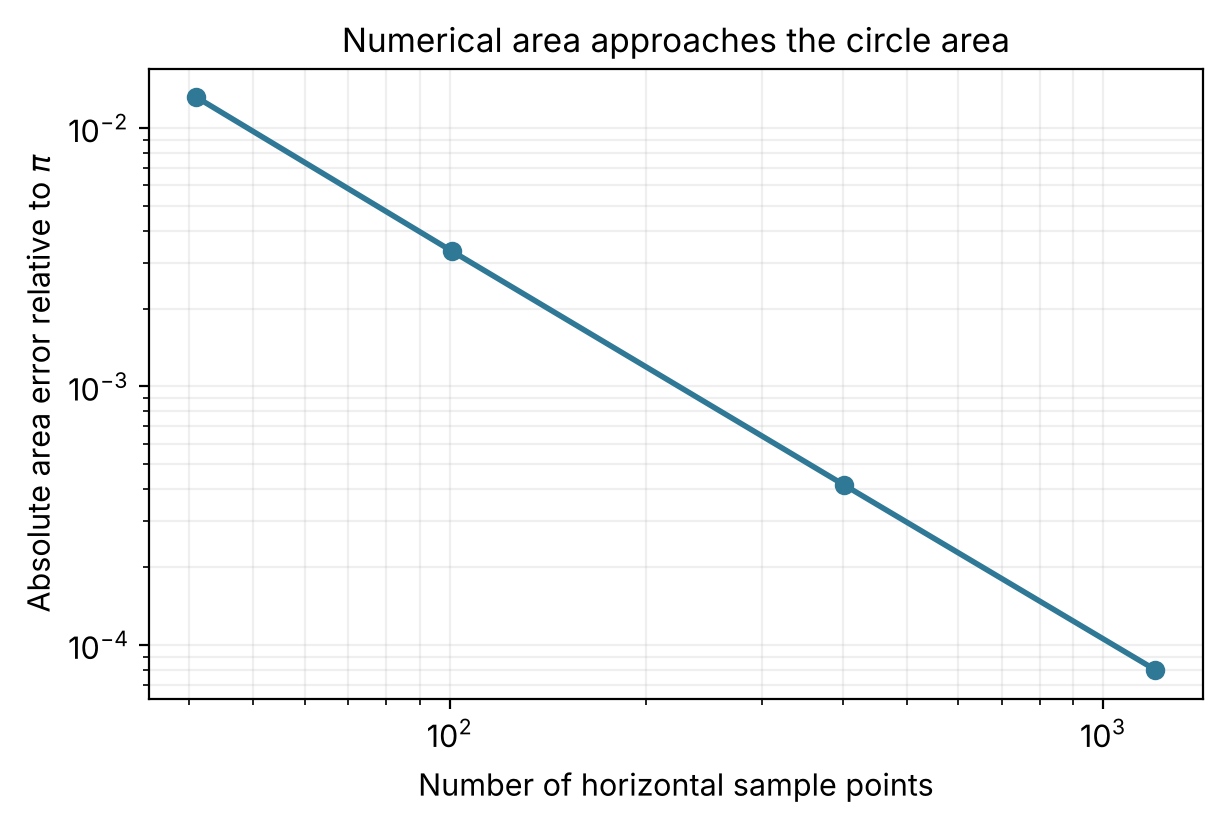

In [27]:
# Create a compact convergence chart with readable log scales.
fig, ax = plt.subplots(figsize=(6.0, 4.0), layout="constrained")
# Plot positive errors against the number of horizontal samples.
ax.loglog(area_counts, area_errors, "o-", color=colors["blue"], lw=2.0, markersize=6)
# Identify both measured quantities and the geometric reference.
ax.set(xlabel="Number of horizontal sample points", ylabel=r"Absolute area error relative to $\pi$", title="Numerical area approaches the circle area")
# Add a light grid that works on logarithmic axes.
ax.grid(alpha=0.2, which="both")
# Export and show the convergence figure.
finish_figure(fig, "11_area_convergence")


**Figure 11.** The area error decreases as the number of slices grows. The log axes make several orders of magnitude visible; this plot does not establish an exact convergence rate.


## 8. Optional extension: area of the reflected-ellipse heart

For a polar outline with positive radius, the area can be computed from $A=\tfrac12\int_0^{2\pi}r(\theta)^2\,d\theta$. A trapezoidal sum approximates that integral. MathWorld gives the exact area of the Nick/Wu reflected-ellipse heart as $2\pi/\sqrt3$. The integral formula is optional here; the code repeats the same trapezoid pattern as the previous section.


In [28]:
# Recover positive polar radius from the checked denominator.
reflect_r = 1.0 / np.sqrt(reflect_denominator)
# Build one trapezoid per neighboring angular sample pair.
angular_widths = np.diff(reflect_theta)
# Average the neighboring squared radii for each angular interval.
average_r_squared = 0.5 * (reflect_r[:-1]**2 + reflect_r[1:]**2)
# Multiply the angular sum by one half as required by polar area.
polar_area_estimate = 0.5 * np.sum(average_r_squared * angular_widths)
# Calculate the exact reference area stated by MathWorld.
polar_area_reference = 2.0 * np.pi / np.sqrt(3.0)
# Check agreement to a reasonable finite-grid accuracy.
assert abs(polar_area_estimate - polar_area_reference) < 1e-4
# Report both values rather than treating the reference as the computed answer.
print(f"Reflected heart area: numerical {polar_area_estimate:.6f}, reference {polar_area_reference:.6f}")


Reflected heart area: numerical 3.627599, reference 3.627599


## 9. Compare and create

The four main constructions use different instructions to reach a related visual goal. The final gallery keeps equal coordinate units within every panel, but each equation has its own natural scale. **Discuss:** which equation is easiest to sample in order along its boundary? Which one needs a two-dimensional grid? Which admits a hand-checked area argument?


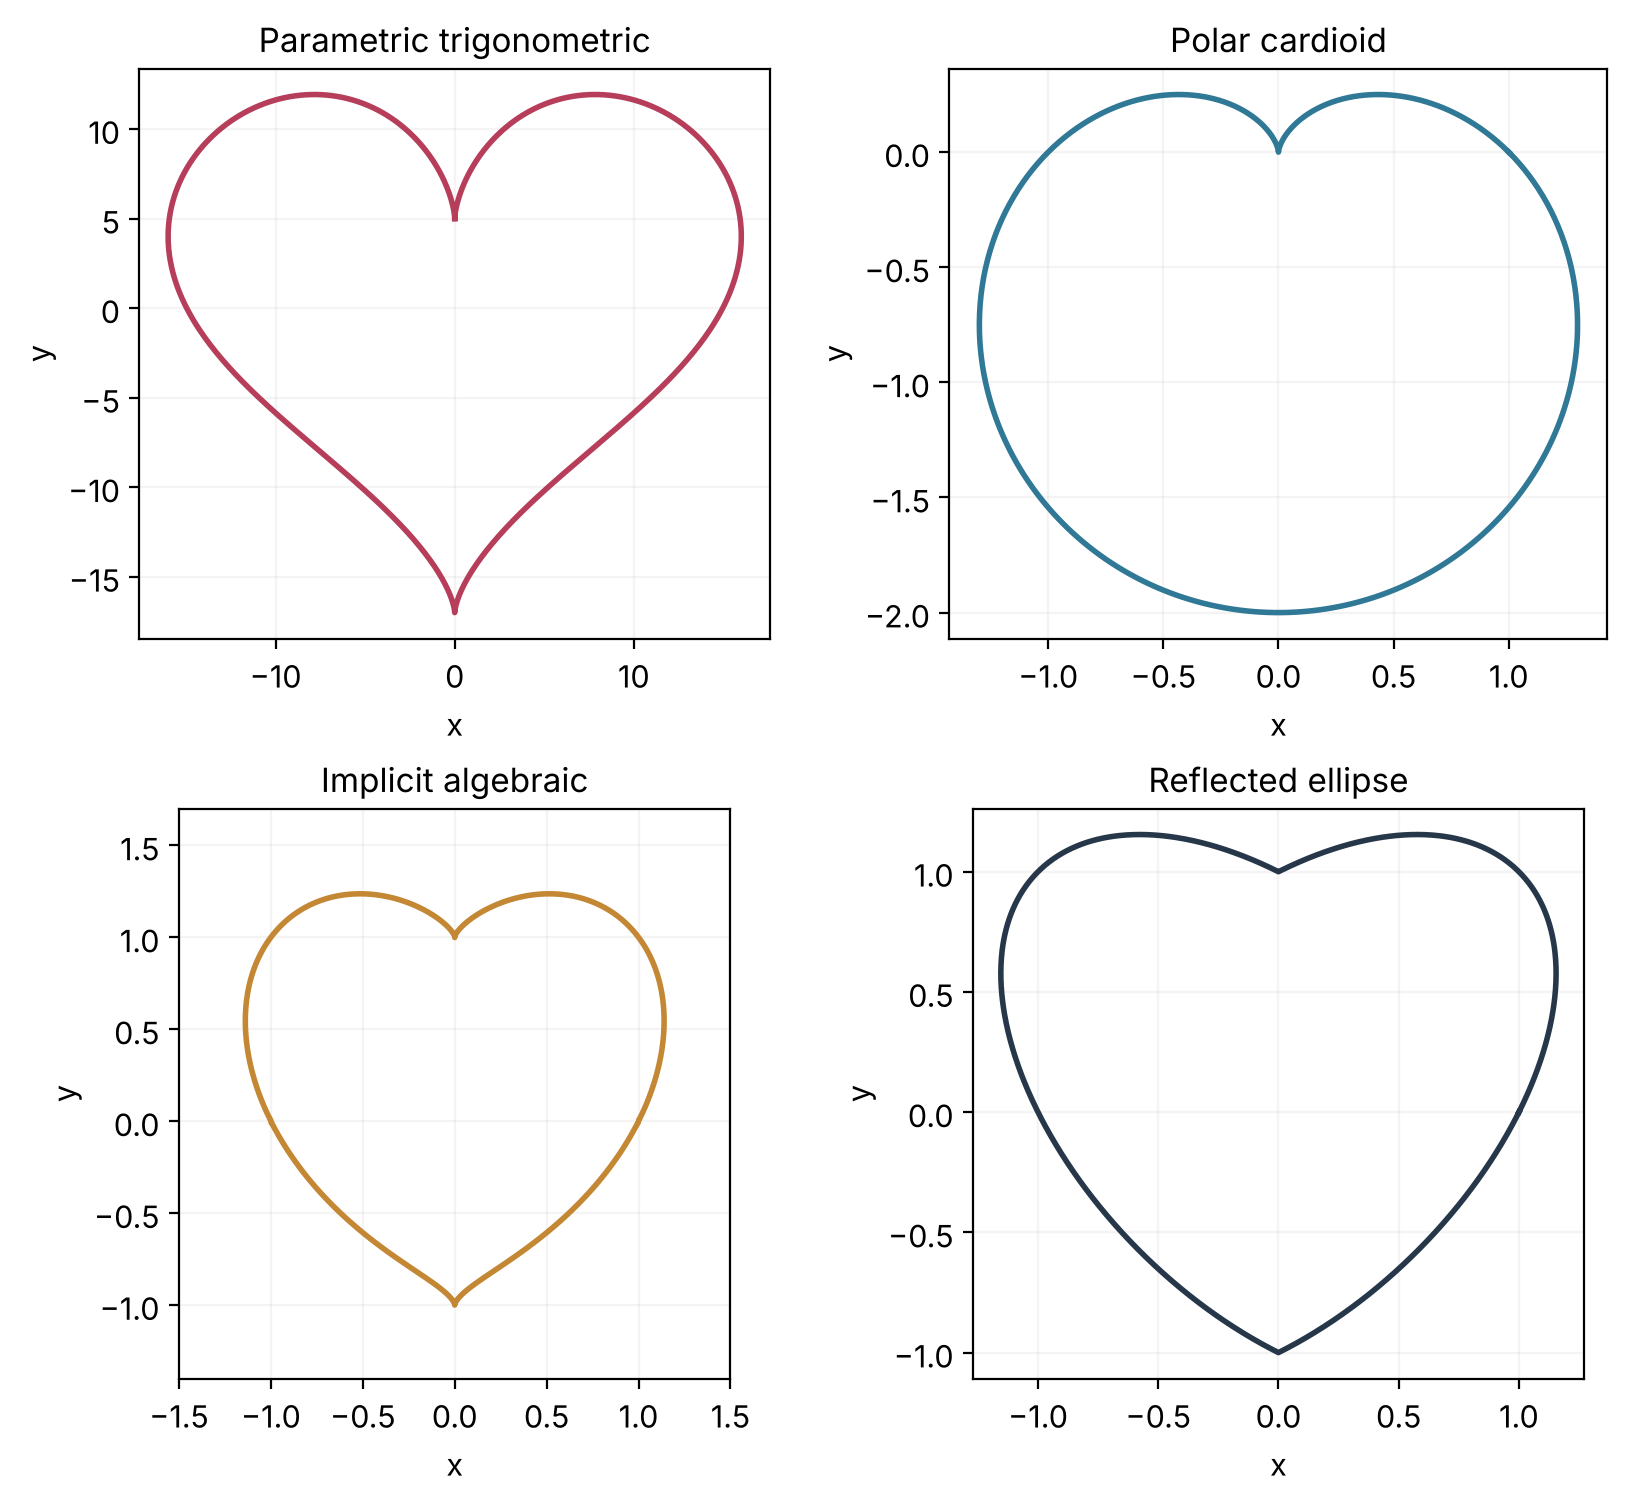

In [29]:
# Create a four-panel gallery of different mathematical heart definitions.
fig, axes = plt.subplots(2, 2, figsize=(8.1, 7.4), layout="constrained")
# Draw the classical parameterized outline in the upper left.
axes[0, 0].plot(heart_x, heart_y, color=colors["rose"], lw=2.0)
# Draw the cardioid in the upper right.
axes[0, 1].plot(cardioid_x, cardioid_y, color=colors["blue"], lw=2.0)
# Draw the algebraic zero contour in the lower left.
axes[1, 0].contour(X, Y, F, levels=[0.0], colors=[colors["gold"]], linewidths=2.0)
# Draw the reflected ellipse in the lower right.
axes[1, 1].plot(reflect_x, reflect_y, color=colors["ink"], lw=2.0)
# Give each panel its own exact formula family as a title.
gallery_titles = ["Parametric trigonometric", "Polar cardioid", "Implicit algebraic", "Reflected ellipse"]
# Traverse axes and labels together to apply consistent presentation.
for ax, title in zip(axes.flat, gallery_titles):
    # Keep each curve geometrically undistorted.
    ax.set_aspect("equal", adjustable="box")
    # Use the same coordinate words while allowing different numerical ranges.
    ax.set(xlabel="x", ylabel="y", title=title)
    # Let a light grid support comparison without hiding the curves.
    ax.grid(alpha=0.13)
# Save and display the compact comparison.
finish_figure(fig, "12_four_heart_gallery")


**Figure 12.** “Heart curve” describes several geometries. The sampling method depends on whether coordinates are specified parametrically, by radius and angle, or implicitly.


## Your design brief

1. **Predict and change.** In a copy of the notebook, change the cardioid parameter $a$ between $0$ and $1$. Predict when the zero-radius cusp first appears, then verify it in the plot and with a numerical check.
2. **Sampling budget.** Use the midpoint diagnostic to find the smallest number of equal parameter intervals among $16,32,64,128,256,512$ with discrepancy below $0.05$ coordinate units. Report your result and why this particular midpoint test is limited.
3. **Symmetry test.** Intentionally change one term in the trigonometric $y(t)$ formula from cosine to sine. Which existing assertion should fail? Explain what geometric property was lost.
4. **Geometry experiment.** Multiply the greeting-card heart's vertical coordinates by $1.5$. Predict its enclosed area from the slice argument, then check it with `slice_area`. Keep the plot's x and y units equal so the change is visible.
5. **Optional challenge.** Animate a dot moving along a parameterized curve, or export a design with a specified physical width. A machine-ready path would additionally need scale, tolerances, closure, and process constraints.

**What to remember:** equations become drawings through coordinate generation and sampling; equal axis scaling keeps geometry honest; symmetry, domain, residual, and area checks catch mistakes that a pleasing picture can hide. Different formulas can all look like hearts while encoding different mathematical constructions.

**Sources and attribution:** [Eric W. Weisstein, “Heart Curve,” MathWorld](https://mathworld.wolfram.com/HeartCurve.html) and its companion `HeartCurve.nb` (parametric, implicit, polar examples and reference areas); [Nick's 2014 answer on the reflected-ellipse heart](https://math.stackexchange.com/a/969748); [Frederick Wu's 2025 polar form and discussion](https://community.wolfram.com/t/various-heart-shaped-curves-from-a-japanese-series/25155/7). We used the mathematical equations as references and drew new figures with Python.
